# Ítem 3: Ensamble clasificador (VotingClassifier) vs. modelos individuales

> **Enunciado:** Entrene un modelo ensemble clasificador, y compare su eficiencia con respecto a un modelo individual. ¿Cuál es mejor?

## Objetivo y fundamento teórico

El **aprendizaje por ensambles** combina varios modelos base para compensar sus errores individuales.
El **clasificador por votación** (`VotingClassifier`) entrena **algoritmos distintos sobre el mismo conjunto de datos**:

* **Votación dura (hard):** $\hat{y} = \operatorname{moda}\{h_1(x), h_2(x), \dots, h_M(x)\}$
* **Votación suave (soft):** $\hat{y} = \arg\max_c \frac{1}{M}\sum_{m=1}^{M} P_m(y=c\mid x)$

El ensamble mejora cuando los modelos base son **precisos y diversos** (cometen errores poco correlacionados).
Se combinan tres sesgos inductivos distintos: **Regresión Logística** (frontera lineal), **K-Vecinos**
(basado en distancias, no paramétrico) y **Árbol de decisión CART** (cortes ortogonales).

**Dataset:** *Pima Indians Diabetes* (768 pacientes, 8 variables clínicas, objetivo: diabetes sí/no). Se eligió
por ser un problema realista y difícil (fronteras solapadas), donde las diferencias entre modelos son visibles.

In [1]:
# ==============================================================================
# Configuración global, reproducibilidad y carga de utilidades comunes
# ==============================================================================
import json, os, sys, time, urllib.request, warnings

# Descargar ml_utils.py si no existe localmente
if not os.path.exists("ml_utils.py") and not os.path.exists("src/ml_utils.py"):
    url = "https://raw.githubusercontent.com/Edwardmamani/ML-UNAP-Tarea-Ejecucion-03/main/ml_utils.py"
    urllib.request.urlretrieve(url, "ml_utils.py")

for p in [".", "..", "src", "../src"]:
    if os.path.exists(p) and p not in sys.path:
        sys.path.insert(0, p)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

from ml_utils import (
    RANDOM_STATE,
    REPO_RAW,
    bootstrap_ci,
    load_csv,
    plot_roc,
    save_results,
    savefig,
    setup_environment,
)

setup_environment(RANDOM_STATE)
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.9.1 | pandas 3.1.0 | numpy 2.4.6


## 1. Carga, calidad de datos y tratamiento de faltantes

In [2]:
ZERO_AS_NAN = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df = load_csv("diabetes.csv")
print("Dimensiones:", df.shape, "| duplicados:", int(df.duplicated().sum()))
print("Ceros fisiológicamente imposibles por columna:")
print((df[ZERO_AS_NAN] == 0).sum())
df[ZERO_AS_NAN] = df[ZERO_AS_NAN].replace(0, np.nan)      # un 0 en glucosa/IMC/presión = dato faltante
X, y = df.drop(columns="Outcome"), df["Outcome"]
print("\nDistribución de clases (1 = diabetes):", y.value_counts().to_dict(),
      f"| prevalencia = {y.mean():.3f}")

Dimensiones: (768, 9) | duplicados: 0
Ceros fisiológicamente imposibles por columna:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Distribución de clases (1 = diabetes): {0: 500, 1: 268} | prevalencia = 0.349


_(análisis pendiente)_

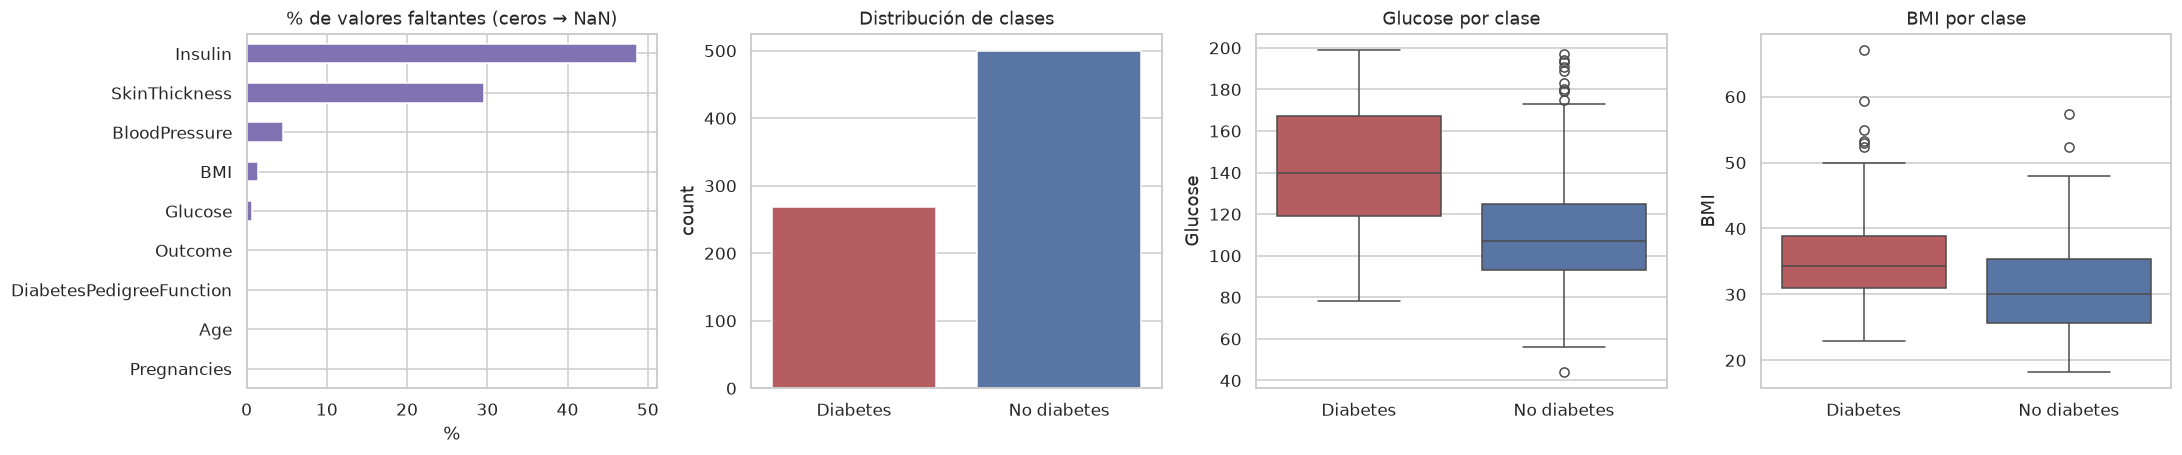

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.3))
(df.isna().mean() * 100).sort_values().plot(kind="barh", ax=axes[0], color="#8172B3")
axes[0].set_title("% de valores faltantes (ceros → NaN)"); axes[0].set_xlabel("%")
lab = y.map({0: "No diabetes", 1: "Diabetes"}); pal = {"No diabetes": "#4C72B0", "Diabetes": "#C44E52"}
sns.countplot(x=lab, hue=lab, palette=pal, legend=False, ax=axes[1]); axes[1].set_title("Distribución de clases")
axes[1].set_xlabel("")
for ax, feat in zip(axes[2:], ["Glucose", "BMI"]):
    sns.boxplot(x=lab, y=df[feat], hue=lab, palette=pal, legend=False, ax=ax); ax.set_xlabel("")
    ax.set_title(f"{feat} por clase")
plt.tight_layout(); savefig("item3_eda"); plt.show()

_(análisis pendiente)_

## 2. Partición estratificada 80/20

In [4]:
from sklearn.model_selection import train_test_split, StratifiedKFold

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y,
                                                    random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (614, 8) | Test: (154, 8)


## 3. Modelos individuales (ajuste de hiperparámetros con validación cruzada)

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

def imputer():
    # mediana ajustada solo con train + indicadores binarios de "dato faltante"
    return SimpleImputer(strategy="median", add_indicator=True)

base = {
    "Regresión Logística": (Pipeline([("imp", imputer()), ("sc", StandardScaler()),
                                      ("clf", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))]),
                            {"clf__C": [0.01, 0.1, 1, 10]}),
    "KNN": (Pipeline([("imp", imputer()), ("sc", StandardScaler()), ("clf", KNeighborsClassifier())]),
            {"clf__n_neighbors": [5, 11, 15, 21, 27, 35], "clf__weights": ["uniform", "distance"]}),
    "Árbol de decisión": (Pipeline([("imp", imputer()),
                                    ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
                          {"clf__max_depth": [2, 3, 4, 5, 6, 8],
                           "clf__min_samples_leaf": [1, 5, 10, 20, 0.05, 0.13]}),
}
tuned = {}
for name, (pipe, grid) in base.items():
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="accuracy", n_jobs=-1).fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    print(f"{name:20s} mejores params: {gs.best_params_} | Acc CV = {gs.best_score_:.4f}")

Regresión Logística  mejores params: {'clf__C': 1} | Acc CV = 0.7834


KNN                  mejores params: {'clf__n_neighbors': 27, 'clf__weights': 'uniform'} | Acc CV = 0.7689


Árbol de decisión    mejores params: {'clf__max_depth': 3, 'clf__min_samples_leaf': 20} | Acc CV = 0.7607


_(análisis pendiente)_

## 4. Ensambles por votación (hard y soft)

In [6]:
from sklearn.ensemble import VotingClassifier
from sklearn.base import clone

estimators = [("lr", clone(tuned["Regresión Logística"])), ("knn", clone(tuned["KNN"])),
              ("dt", clone(tuned["Árbol de decisión"]))]
models = dict(tuned)
models["Voting (hard)"] = VotingClassifier(estimators=estimators, voting="hard")
models["Voting (soft)"] = VotingClassifier(estimators=[(n, clone(e)) for n, e in estimators], voting="soft")
list(models)

['Regresión Logística',
 'KNN',
 'Árbol de decisión',
 'Voting (hard)',
 'Voting (soft)']

## 5. Evaluación: validación cruzada 10-Fold y conjunto de prueba

In [7]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, balanced_accuracy_score)

rows, cv_acc = [], {}
for name, model in models.items():
    has_proba = hasattr(model, "predict_proba")
    scoring = ["accuracy", "f1", "balanced_accuracy"] + (["roc_auc"] if has_proba else [])
    cvres = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None
    cv_acc[name] = cvres["test_accuracy"]
    rows.append({
        "Modelo": name,
        "Acc. train": accuracy_score(y_train, model.predict(X_train)),
        "Acc. CV (media)": cvres["test_accuracy"].mean(),
        "Acc. CV (std)": cvres["test_accuracy"].std(),
        "F1 CV": cvres["test_f1"].mean(),
        "ROC-AUC CV": cvres["test_roc_auc"].mean() if has_proba else np.nan,
        "Acc. test": accuracy_score(y_test, y_pred),
        "Acc. balanceada test": balanced_accuracy_score(y_test, y_pred),
        "Precisión test": precision_score(y_test, y_pred),
        "Recall test": recall_score(y_test, y_pred),
        "F1 test": f1_score(y_test, y_pred),
        "ROC-AUC test": roc_auc_score(y_test, y_proba) if y_proba is not None else np.nan,
    })
results = pd.DataFrame(rows).set_index("Modelo")
results.round(4)

,Acc. train,Acc. CV (media),Acc. CV (std),F1 CV,ROC-AUC CV,Acc. test,Acc. balanceada test,Precisión test,Recall test,F1 test,ROC-AUC test
Modelo,,,,,,,,,,,
Regresión Logística,0.7948,0.7834,0.0464,0.6503,0.8388,0.7143,0.6735,0.6042,0.5370,0.5686,0.8178
KNN,0.7834,0.7689,0.0498,0.5924,0.8259,0.7338,0.6800,0.6585,0.5000,0.5684,0.7894
Árbol de decisión,0.7606,0.7607,0.0386,0.5515,0.7724,0.6948,0.5989,0.6522,0.2778,0.3896,0.7801
Voting (hard),0.7932,0.7835,0.0443,0.6248,NaN,0.7143,0.6522,0.6316,0.4444,0.5217,NaN
Voting (soft),0.7997,0.7819,0.0380,0.6306,0.8397,0.7338,0.6715,0.6757,0.4630,0.5495,0.8154


_(análisis pendiente)_

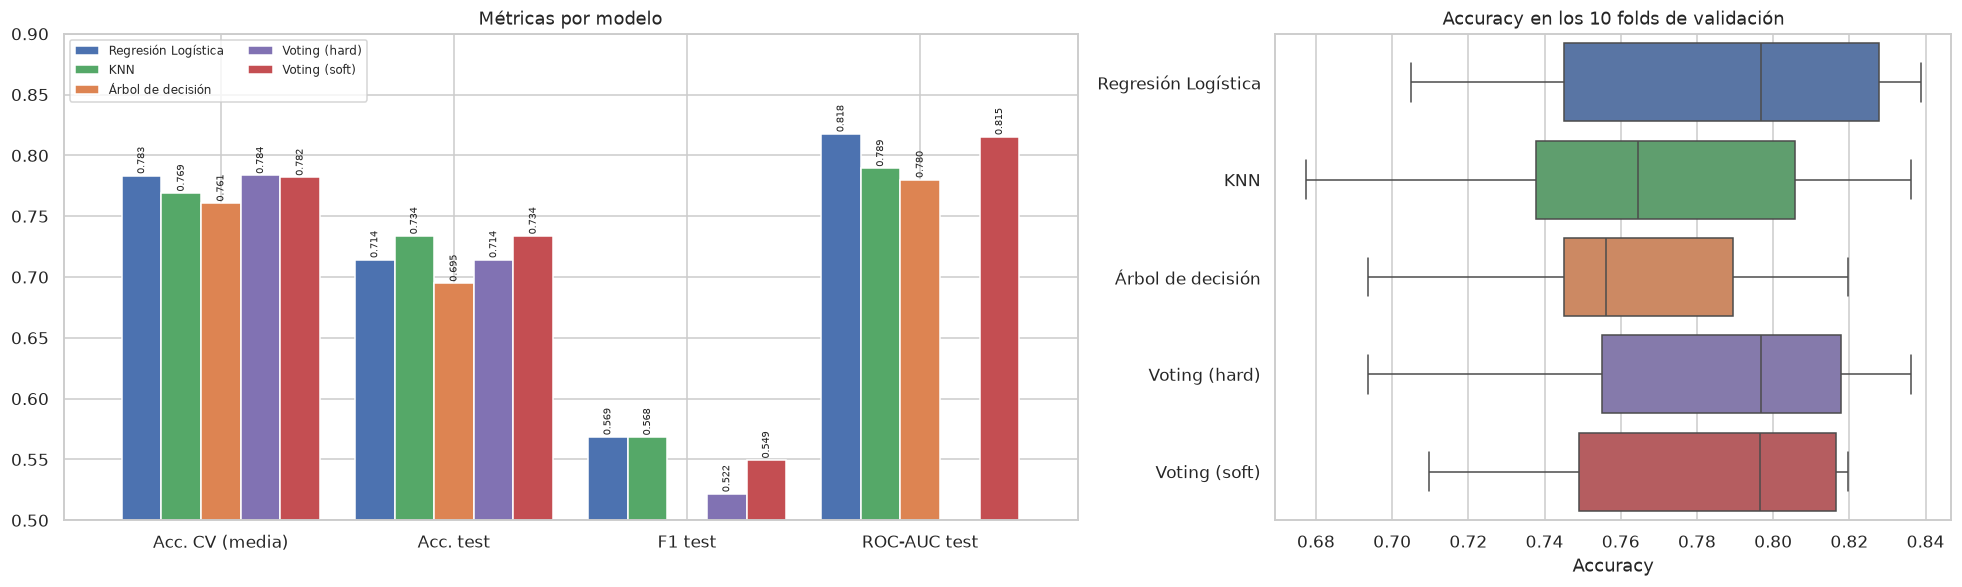

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5), gridspec_kw={"width_ratios": [1.5, 1]})
colors = ["#4C72B0", "#55A868", "#DD8452", "#8172B3", "#C44E52"]
results[["Acc. CV (media)", "Acc. test", "F1 test", "ROC-AUC test"]].T.plot(
    kind="bar", ax=axes[0], color=colors, width=0.85)
axes[0].set_ylim(0.5, 0.9); axes[0].set_title("Métricas por modelo"); axes[0].tick_params(axis="x", rotation=0)
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.3f", fontsize=6.5, padding=1, rotation=90)
axes[0].legend(loc="upper left", fontsize=8, ncol=2)
cv_df = pd.DataFrame(cv_acc).melt(var_name="Modelo", value_name="Accuracy")
sns.boxplot(data=cv_df, y="Modelo", x="Accuracy", hue="Modelo", palette=colors, legend=False, ax=axes[1])
axes[1].set_title("Accuracy en los 10 folds de validación"); axes[1].set_ylabel("")
plt.tight_layout(); savefig("item3_comparacion"); plt.show()

_(análisis pendiente)_

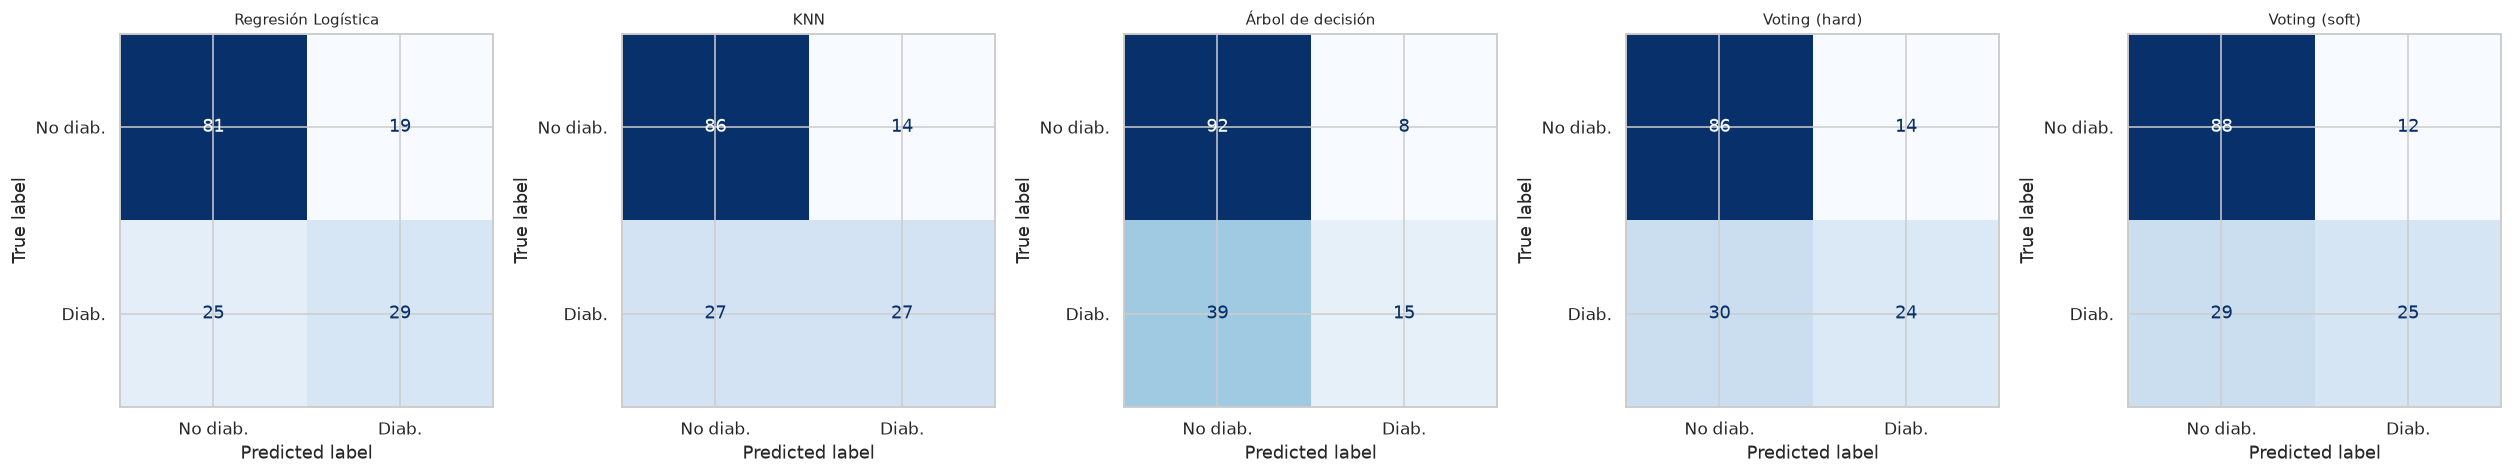

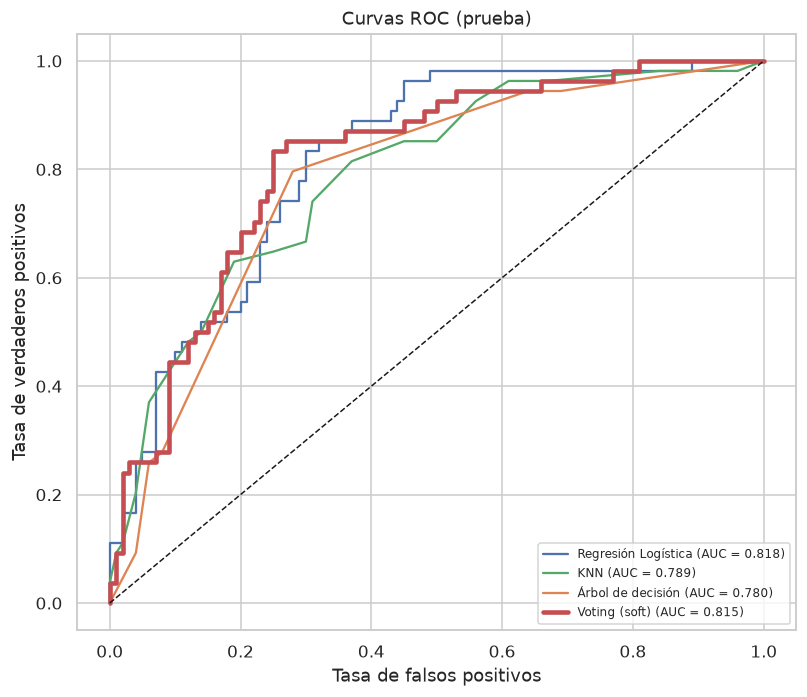

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 5, figsize=(23, 4.3))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test), display_labels=["No diab.", "Diab."],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name, fontsize=10)
plt.tight_layout(); savefig("item3_confusion"); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 6.5))
for (name, model), col in zip(models.items(), colors):
    if hasattr(model, "predict_proba"):
        plot_roc(ax, model, X_test, y_test, name, color=col,
                                       lw=3 if "soft" in name else 1.5)
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_title("Curvas ROC (prueba)")
plt.tight_layout(); savefig("item3_roc"); plt.show()

_(análisis pendiente)_

## 6. ¿Por qué funciona el ensamble? Diversidad de errores y fronteras de decisión

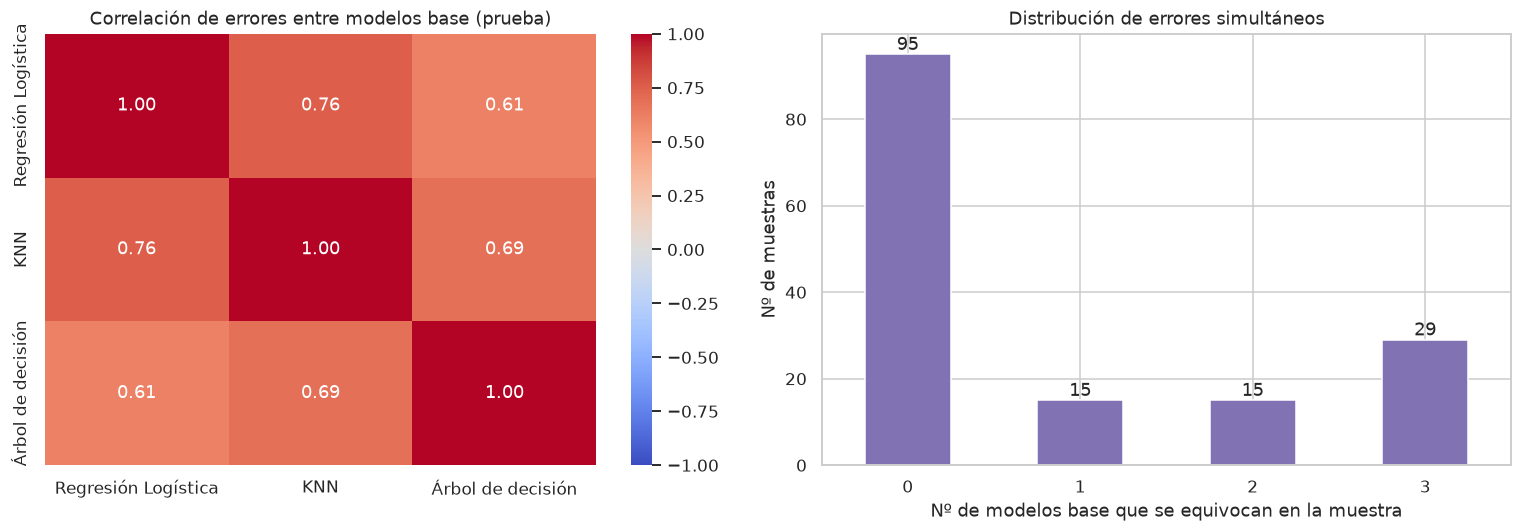

Muestras en que exactamente 1 modelo base falla (la votación mayoritaria puede corregirlas): 15


In [10]:
errs = pd.DataFrame({n: (tuned[n].predict(X_test) != y_test).astype(int).values for n in tuned})
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(errs.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Correlación de errores entre modelos base (prueba)")
n_err = errs.sum(axis=1).value_counts().sort_index()
n_err.plot(kind="bar", ax=axes[1], color="#8172B3")
axes[1].set_xlabel("Nº de modelos base que se equivocan en la muestra"); axes[1].set_ylabel("Nº de muestras")
axes[1].set_title("Distribución de errores simultáneos"); axes[1].tick_params(axis="x", rotation=0)
for c in axes[1].containers:
    axes[1].bar_label(c)
plt.tight_layout(); savefig("item3_diversidad"); plt.show()
print("Muestras en que exactamente 1 modelo base falla (la votación mayoritaria puede corregirlas):",
      int((errs.sum(axis=1) == 1).sum()))

_(análisis pendiente)_

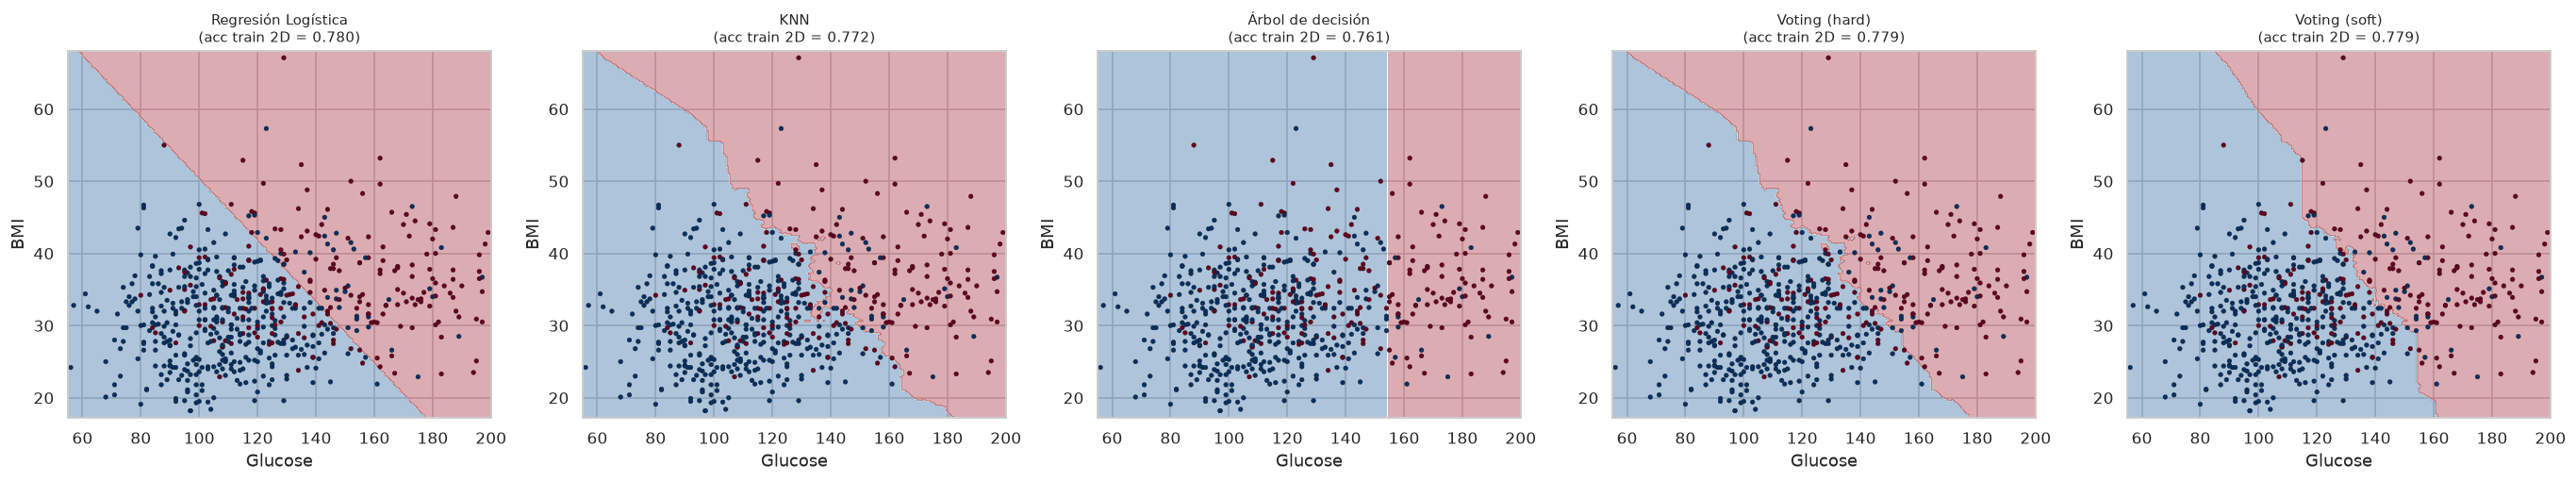

In [11]:
from sklearn.inspection import DecisionBoundaryDisplay

f2 = ["Glucose", "BMI"]
X2_tr = SimpleImputer(strategy="median").fit(X_train[f2])
X2_train = pd.DataFrame(X2_tr.transform(X_train[f2]), columns=f2)
fig, axes = plt.subplots(1, 5, figsize=(25, 4.8))
for ax, (name, model) in zip(axes, models.items()):
    m2 = clone(model).fit(X2_train, y_train)
    DecisionBoundaryDisplay.from_estimator(m2, X2_train, response_method="predict", cmap="RdBu_r",
                                           alpha=0.35, ax=ax, grid_resolution=250)
    ax.scatter(X2_train["Glucose"], X2_train["BMI"], c=y_train, cmap="RdBu_r", s=10, edgecolor="k", lw=0.2)
    ax.set_title(f"{name}\n(acc train 2D = {m2.score(X2_train, y_train):.3f})", fontsize=10)
plt.tight_layout(); savefig("item3_fronteras"); plt.show()

_(análisis pendiente)_

## 7. Significancia estadística (CV repetida 10×3 + Wilcoxon) e IC bootstrap

In [12]:
from scipy.stats import wilcoxon
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

rcv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=RANDOM_STATE)
rep = {n: cross_val_score(models[n], X_train, y_train, cv=rcv, scoring="accuracy", n_jobs=-1) for n in models}
stats_rows = []
for ens in ["Voting (soft)", "Voting (hard)"]:
    for ind in tuned:
        p = wilcoxon(rep[ens], rep[ind], zero_method="zsplit").pvalue
        stats_rows.append({"Comparación": f"{ens} vs {ind}", "Acc. ensamble": rep[ens].mean(),
                           "Acc. individual": rep[ind].mean(), "Diferencia": (rep[ens] - rep[ind]).mean(),
                           "p-valor Wilcoxon": p, "Significativo (α=0.05)": "Sí" if p < 0.05 else "No"})
stats_df = pd.DataFrame(stats_rows)
ci_df = pd.DataFrame({n: bootstrap_ci(y_test, models[n].predict(X_test), accuracy_score) for n in models},
                     index=["IC95% inf", "IC95% sup"]).T
rep_df = pd.DataFrame({n: [v.mean(), v.std()] for n, v in rep.items()}, index=["Acc. media 30 folds", "std"]).T
display(rep_df.round(4)); display(stats_df.round(4)); display(ci_df.round(4))

,Acc. media 30 folds,std
Regresión Logística,0.7807,0.0448
KNN,0.7607,0.0434
Árbol de decisión,0.7482,0.0366
Voting (hard),0.7726,0.0403
Voting (soft),0.7737,0.0397


,Comparación,Acc. ensamble,Acc. individual,Diferencia,p-valor Wilcoxon,Significativo (α=0.05)
0,Voting (soft) vs Regresión Logística,0.7737,0.7807,-0.0070,0.1453,No
1,Voting (soft) vs KNN,0.7737,0.7607,0.0130,0.1354,No
2,Voting (soft) vs Árbol de decisión,0.7737,0.7482,0.0255,0.0001,Sí
3,Voting (hard) vs Regresión Logística,0.7726,0.7807,-0.0081,0.2311,No
4,Voting (hard) vs KNN,0.7726,0.7607,0.0119,0.0540,No
5,Voting (hard) vs Árbol de decisión,0.7726,0.7482,0.0244,0.0002,Sí


,IC95% inf,IC95% sup
Regresión Logística,0.6364,0.7792
KNN,0.6623,0.8052
Árbol de decisión,0.6169,0.7662
Voting (hard),0.6364,0.7792
Voting (soft),0.6558,0.7987


_(análisis pendiente)_

In [13]:
save_results({
    "results": results.reset_index().to_dict(orient="records"),
    "best_params": {n: {k: (v if not isinstance(v, float) else float(v)) for k, v in m.get_params().items()
                        if k.startswith("clf__") and k.split("__")[1] in
                        ("C", "n_neighbors", "weights", "max_depth", "min_samples_leaf")}
                    for n, m in tuned.items()},
    "repeated_cv": rep_df.reset_index().rename(columns={"index": "Modelo"}).to_dict(orient="records"),
    "stats": stats_df.to_dict(orient="records"),
    "ci": ci_df.reset_index().rename(columns={"index": "Modelo"}).to_dict(orient="records"),
    "error_corr": errs.corr().round(3).to_dict(),
}, "item3")
print("Resultados guardados en results/item3.json")

Resultados guardados en results/item3.json


## Conclusiones
_(pendiente)_